In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt #Needed for visualization

In [21]:
np.random.seed(42)

n = 100

study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)

final_score = (
    0.5 * study_hours
    + 0.3 * attendance
    + 0.2 * previous_mark
    + np.random.normal(0, 5, n)
)

df = pd.DataFrame({
    "study_hours": study_hours,
    "attendance": attendance,
    "previous_mark": previous_mark,
    "final_score": final_score
})

df.loc[0:5, "study_hours"] = np.nan #Missing values
df.loc[99, "study_hours"] = 50     #Outlier
df.loc[98, "attendance"] = -10     #Impossible value

print(df)
# df.to_csv('student_data.csv', index=False)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


Part A: Inspect and Clean

In [22]:
df.shape #Give the number of Rows and Columns

(100, 4)

In [23]:
df.isnull().sum()   # Count missing values in each column

study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64

In [24]:
df[df["study_hours"] > 10]  #Find the outliers in study_hours

,study_hours,attendance,previous_mark,final_score
99,50.0,73.570297,79.444433,46.41447


In [25]:
df[df["attendance"] < 0]  #Find any impossible value in attendance column

,study_hours,attendance,previous_mark,final_score
98,5.010227,-10.0,82.192932,44.045627


As for the outlier value of 50 found in study_hours, I would cap it to 10 hours maximum because then study_hour can not pass 24 hours logically in a day and practically a student can not study more than 10 hours effectively (This is my personal assumption). We will not just remove the row because it may still be useful for another inspections.

In [26]:
df["study_hours"] = df["study_hours"].clip(upper=10) #Cap the study_hours to 10 hours maximum
df["study_hours"].nlargest(1) #Now check the largest value

99    10.0
Name: study_hours, dtype: float64

In [27]:
# Separate features and target
X = df[["study_hours", "attendance", "previous_mark"]] #Feauture matrices are those inputs used for prediction 
y = df["final_score"] #The target variable is the value we want to predict

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Numerical columns:", X.select_dtypes(include=np.number).columns.tolist())

Feature matrix shape: (100, 3)
Target shape: (100,)
Numerical columns: ['study_hours', 'attendance', 'previous_mark']


Part B: Summarize

In [28]:
# Calculate the mean of every column
print("MEAN")
print(df.mean())

# Calculate the median of every column
print("\nMEDIAN")
print(df.median())

# Calculate the standard deviation of every column
print("\nSTANDARD DEVIATION")
print(df.std())

MEAN
study_hours       4.793384
attendance       84.267225
previous_mark    70.973444
final_score      42.691957
dtype: float64

MEDIAN
study_hours       4.812342
attendance       85.841072
previous_mark    71.465436
final_score      42.763014
dtype: float64

STANDARD DEVIATION
study_hours       1.909881
attendance       13.476443
previous_mark    16.264243
final_score       6.086797
dtype: float64


Observations
1. The mean attendance is lower than the median attendance which means that there are possibily very lower attendance rates for some students compared to most of the students. (May be the impossible -10 value)
2. The standard deviation for previous_mark column is relatively high, which merans that there is more variation and inconsistency among the previous marks of the students.
3. For the study_hours column the mean and the median are relatively close and the standard deviation is relatively low, which means the study hours among the students is relatively concentrated around the average.

Part C: Visualize

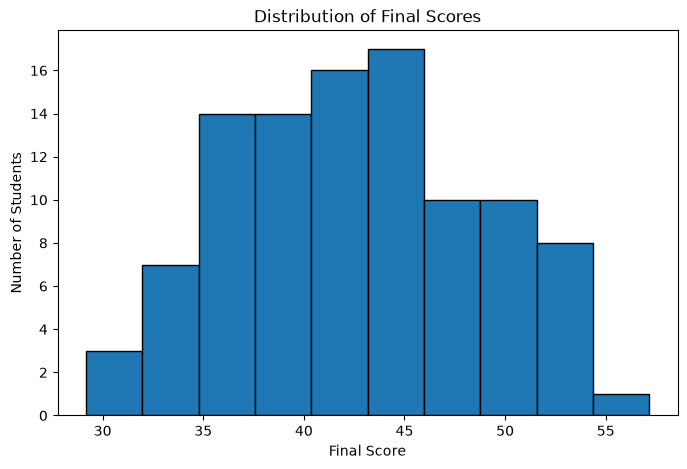

In [29]:
#Histogram for final_score
plt.figure(figsize=(8, 5))

plt.hist(df["final_score"], bins=10, edgecolor="black")

plt.title("Distribution of Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")

plt.show()

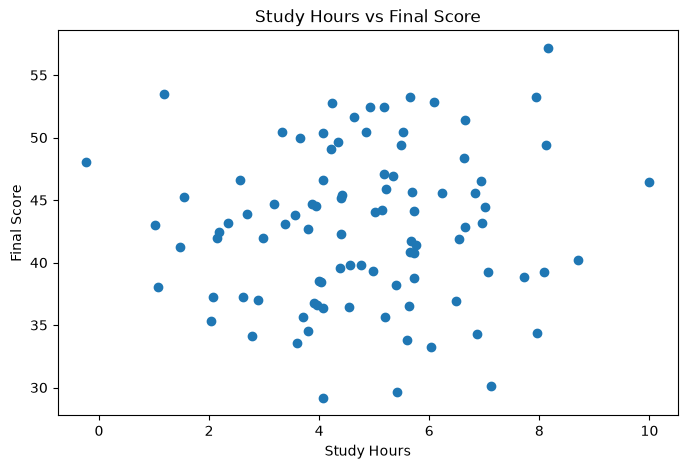

In [30]:
#Scatter plot of study_hours vs final_score
plt.figure(figsize=(8, 5))

plt.scatter(df["study_hours"], df["final_score"])

plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours")
plt.ylabel("Final Score")

plt.show()

The histogram of final_score shows a roughly symmetric distribution, with scores distributed around the center. This suggests that the final scores are relatively balanced around the middle.
The scatter plot shows a weak positive relationship between study_hours and final_score. This suggests that students who study more hours tend to achieve slightly higher final scores but the relationship is not strong. Other factors such as attendance, previous marks and random variation may also influence students final scores.

Part D: Correlation and Casuality

In [31]:
correlation = df["study_hours"].corr(df["final_score"])

print("Pearson correlation coefficient:", correlation)

Pearson correlation coefficient: 0.06658058032736104


The lower Pearson Correlation value indicates very weak positive linear relationship between study_hours and final_scores. Correlation does not guarantee a specific score for a student who studies for 10 hours. It describes the overall relationship between study_hours and final_scores.
Potential confounding variables that affect the link between study_hours and final_scores could be attendance and previos_marks of the students.

Part E: Vectors and Dot Products

In [40]:
#One student on row 98 is selected, excluding the target column
x = df.loc[97, ["study_hours", "attendance", "previous_mark"]].to_numpy(dtype=float)

print("Student feature vector:", x)

Student feature vector: [ 5.52211054 86.53725106 74.60949281]


In [41]:
# Define the weight vector and bias
w = np.array([0.5, 0.2, 0.4])
b = 5

print("Weights:", w)
print("Bias:", b)

Weights: [0.5 0.2 0.4]
Bias: 5


In [42]:
# Calculate the weighted sum and add the bias
y_pred = np.dot(w, x) + b

print("Predicted value:", y_pred)

Predicted value: 54.9123026093306


The weight vector represents the contribution assigned to each feature in the prediction calculation. The weights are multiplied by study hours, attendance and previous marks respectively.
The bias is the constant value 5 added to the weighted sum. It shifts the calculated prediction by five units.
The calculated value is the model's predicted value for the selected student based on the given features, weights, and bias. It is a mathematical demonstration of a weighted prediction, not necessarily an accurate final-score prediction.

Part F: Scaling

In [44]:
# Standardize study_hours and previous_mark
df["study_hours_standardized"] = (
    df["study_hours"] - df["study_hours"].mean()
) / df["study_hours"].std()

df["previous_mark_standardized"] = (
    df["previous_mark"] - df["previous_mark"].mean()
) / df["previous_mark"].std()

print(df[[
    "study_hours_standardized",
    "previous_mark_standardized"
]].head(20))

    study_hours_standardized  previous_mark_standardized
0                        NaN                    0.270124
1                        NaN                    0.457342
2                        NaN                    0.939012
3                        NaN                    0.912037
4                        NaN                   -1.330433
5                        NaN                   -0.924778
6                   1.761911                    0.415149
7                   0.911829                    0.413997
8                  -0.383444                    0.415161
9                   0.676344                    3.493401
10                 -0.377102                    0.466663
11                 -0.379523                    0.987445
12                  0.361562                    0.819994
13                 -1.895377                    0.540906
14                 -1.698127                   -0.350615
15                 -0.480637                    0.640122
16                 -0.952440   

Feature scaling is important because KNN uses distances to determine which data points are closest to each other. If one feature has a much larger numerical scale than another, it can dominate the distance calculation. Standardization puts features on a comparable scale, helping each feature contribute more fairly to the distance calculation.